# ✨​ Take bounding boxes and predict segmentation masks using SAM2

The bounding boxes we saved in a geopackage file, we will convert them again to the pixel scale and feed them to sam to get a segmentation mask for each bounding box

### Some configurations because I ran this in kaggle (i didnt have a gpu)

In [3]:
using_colab = True
if using_colab:
    import torch
    import torchvision
    print("PyTorch version:", torch.__version__)
    print("Torchvision version:", torchvision.__version__)
    print("CUDA is available:", torch.cuda.is_available())
    import sys
    !{sys.executable} -m pip install opencv-python matplotlib
    !{sys.executable} -m pip install 'git+https://github.com/facebookresearch/sam2.git'

    !mkdir -p images
    !wget -P images https://raw.githubusercontent.com/facebookresearch/sam2/main/notebooks/images/truck.jpg
    !wget -P images https://raw.githubusercontent.com/facebookresearch/sam2/main/notebooks/images/groceries.jpg

    !mkdir -p ../checkpoints/
    !wget -P ../checkpoints/ https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_large.pt



PyTorch version: 2.6.0+cu124
Torchvision version: 0.21.0+cu124
CUDA is available: True
  Cloning https://github.com/facebookresearch/sam2.git to /tmp/pip-req-build-6xwkuh9e
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/sam2.git /tmp/pip-req-build-6xwkuh9e
  Resolved https://github.com/facebookresearch/sam2.git to commit 2b90b9f5ceec907a1c18123530e92e794ad901a4
  Installing build dependencies ... ^C
canceled
ERROR: Operation cancelled by user
--2026-01-03 01:49:46--  https://raw.githubusercontent.com/facebookresearch/sam2/main/notebooks/images/truck.jpg
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 271475 (265K) [image/jpeg]
Saving to: ‘images/truck.jpg.1’

truck.jpg.1         100%[===================>] 265.11K  

In [4]:
import os
# if using Apple MPS, fall back to CPU for unsupported ops
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

In [5]:
# select the device for computation
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"using device: {device}")

if device.type == "cuda":
    # use bfloat16 for the entire notebook
    torch.autocast("cuda", dtype=torch.bfloat16).__enter__()
    # turn on tfloat32 for Ampere GPUs (https://pytorch.org/docs/stable/notes/cuda.html#tensorfloat-32-tf32-on-ampere-devices)
    if torch.cuda.get_device_properties(0).major >= 8:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
elif device.type == "mps":
    print(
        "\nSupport for MPS devices is preliminary. SAM 2 is trained with CUDA and might "
        "give numerically different outputs and sometimes degraded performance on MPS. "
        "See e.g. https://github.com/pytorch/pytorch/issues/84936 for a discussion."
    )



using device: cuda


## Now run SAM2

Setting up SAM

In [6]:
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

sam2_checkpoint = "../checkpoints/sam2.1_hiera_large.pt"
model_cfg = "configs/sam2.1/sam2.1_hiera_l.yaml"

sam2_model = build_sam2(model_cfg, sam2_checkpoint, device=device)
mask_predictor = SAM2ImagePredictor(sam2_model)

We will split the orthomosaic into tiles with the bounding boxes in each tile, making sure no bounding box is split between two tiles and each bounding box appears only in one tile. For each tile containing boxes we will make predictions with SAM2.

In [ ]:
import pandas as pd
import numpy as np
from osgeo import gdal
import os
from PIL import Image
import time
import geopandas as gpd
from shapely.strtree import STRtree
from affine import Affine
from rasterio.features import shapes
from shapely.geometry import shape, mapping, box, MultiPolygon
from osgeo import osr
from rasterio.mask import mask
import rasterio

Mosaic class to manage the raster file

In [ ]:
# A class to manage the orthomosaics and its properties
class Mosaic:
    def __init__(self, input_tiff = None):

        if input_tiff:
            self.dataset = gdal.Open(input_tiff)

            if self.dataset is None:
                print(f"Error opening file {input_tiff}")
                exit(1)

            self.image_width = self.dataset.RasterXSize
            self.image_height = self.dataset.RasterYSize

            self.geotransform = self.dataset.GetGeoTransform()
            self.gds_x, self.gds_y = self.get_pixel_cm()

            # Get CRS from dataset
            srs = osr.SpatialReference()
            srs.ImportFromWkt(self.dataset.GetProjectionRef())
            self.crs = srs.ExportToWkt()  # keep WKT form

    def get_pixel_cm(self):
        # Convert pixel size from degrees to centimeters
        pixel_size_x_cm = abs(self.geotransform[1]) * 100
        pixel_size_y_cm = abs(self.geotransform[5]) * 100

        return pixel_size_x_cm, pixel_size_y_cm

    def calculate_tile_size_px(self, tile_width_cm):
        tile_width = int(tile_width_cm / self.gds_x)
        tile_height = int(tile_width_cm / self.gds_y)
        return tile_width, tile_height


    def geospatial_to_pixel_coords(self, cajita, tile_width, tile_height,x_offset,y_offset):
        # Convert geospatial to pixel
        # Convert geo coordinates to pixel coordinates in the full orthomosaic
        xmin, ymin, xmax, ymax = cajita.bounds

        xmin_full_pixel = int((xmin - self.geotransform[0]) / self.geotransform[1])
        xmax_full_pixel = int((xmax - self.geotransform[0]) / self.geotransform[1])
        ymin_full_pixel = int((ymin - self.geotransform[3]) / self.geotransform[5])
        ymax_full_pixel = int((ymax - self.geotransform[3]) / self.geotransform[5])

        # Adjust these pixel coordinates relative to the current tile
        xmin_tile_pixel = max(0, xmin_full_pixel - x_offset)
        xmax_tile_pixel = min(tile_width, xmax_full_pixel - x_offset)
        ymin_tile_pixel = max(0, ymin_full_pixel - y_offset)
        ymax_tile_pixel = min(tile_height, ymax_full_pixel - y_offset)
        boxpixel =  [xmin_tile_pixel,  ymax_tile_pixel, xmax_tile_pixel, ymin_tile_pixel]
        return boxpixel

Helpful functions to show the images with the bounding boxes or with the segmentation masks

In [ ]:
# Function to visualize images with bounding boxes
def visualize_images_with_bboxes(image, bboxes):
        # Plot image
        plt.figure()
        plt.imshow(image)
        # Draw bounding boxes
        for bbox in bboxes:
            xmin, ymin, xmax, ymax = tuple(bbox)
            rect = plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, linewidth=2, edgecolor='red', facecolor='none')
            plt.gca().add_patch(rect)
        plt.axis('off')
        plt.show()


def show_masks(masks_tensor, ax, alpha=0.5):
    """
    Display all masks combined into one image with different colors.

    Parameters:
    - masks_tensor: A 4D PyTorch tensor with shape (x, 1, W, H).
    - ax: Matplotlib Axes object.
    - alpha: Transparency level.
    """
    masks_np = masks_tensor # Convert to NumPy


    num_masks,_,height, width = masks_np.shape

    # Generate distinct random colors for each mask
    colors = np.random.rand(num_masks, 3)  # Shape: (num_masks, RGB)

    # Initialize a blank image for combined masks
    combined_mask = np.zeros((height, width, 3), dtype=np.float32)

    for mask, color in zip(masks_np, colors):
        mask_rgb = np.transpose(mask, (1, 2, 0)).astype(np.float32)
        if mask_rgb.max() > 1.0:
            mask_rgb /= 255.0

        # Create a binary mask (areas where the mask is present)
        binary_mask = mask_rgb.mean(axis=2) > 0

        # Color only where the mask is active
        for c in range(3):
            combined_mask[..., c] += binary_mask * color[c]

    # Normalize combined_mask to avoid values > 1.0
    combined_mask = np.clip(combined_mask, 0, 1)

    # Plot the combined mask
    ax.imshow(combined_mask, alpha=alpha)
    ax.set_title("Combined Masks with Different Colors")
    ax.axis('off')


def print_image_mask(masks, img):
    plt.figure(figsize=(10, 10))  # Create a new figure for each image
    plt.imshow(img)
    show_masks(masks, plt.gca())
    plt.axis('off')
    plt.show()  # Show and reset the plot for the next iteration

Now we use SAM in the images generated from the orthomosaic

In [ ]:
################ PIPELINE ######################

# Save binary geospatial masks to a temporary directory
# We dont want to lose progress in case something crashes
def save_tile_masks_to_temp(tile_name, tile_masks, temp_path, crs):
    gdf = gpd.GeoDataFrame(
        geometry=[geom for geom, _ in tile_masks],
        crs=crs
    )
    out = os.path.join(temp_path, f"{tile_name}.gpkg")
    gdf.to_file(out, driver="GPKG")

# Merge temporary GeoJSON files into a single GeoPackage
def merge_temp_to_geopackage(mosaic, temp_path, output_gpkg):
    temp_files = os.listdir(temp_path)
    gdfs = []
    for f in temp_files:
        gdf = gpd.read_file(os.path.join(temp_path, f))
        # Force CRS if not present
        if gdf.crs is None:
            gdf.set_crs(mosaic.crs, inplace=True)
        gdfs.append(gdf)

    merged = gpd.GeoDataFrame(pd.concat(gdfs, ignore_index=True), crs=mosaic.crs)
    merged.to_file(output_gpkg, driver="GPKG")
    print(f"Saved merged predictions to {output_gpkg}")

    
# Segment bounding boxes in an image and geo-transform the masks using the tile information
def segment_and_geo_transform(mosaic, mask_predictor,tile_image, boxes, tile_xmin, tile_ymin):
    #Predict masks
    mask_predictor.set_image(tile_image)
    with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
        mask_predictor.set_image(tile_image)
        masks, _, _ = mask_predictor.predict(
          point_coords=None,
          point_labels=None,
          box=boxes,
          multimask_output=False
        )
    if masks.shape[0] == 1:
        # reshape mask to have three dimensions
        masks = np.expand_dims(masks, axis=1)

    # print predicted masks
    print_image_mask(masks, tile_image)

    # Convert mask to geospatial coordinates
    tile_masks = []
    for mask in masks:
        # convert mask to geo referenced format
        if len(mask.shape) > 2:
            mask = np.transpose(mask, (1, 2, 0)).squeeze()
        mask = mask.astype(np.uint8)  

        # Create affine transform for the tile
        transform = Affine(
            mosaic.geotransform[1], 0, tile_xmin,
            0, mosaic.geotransform[5], tile_ymin
        )

        # Create a binary mask for this specific ID
        mask_geom = [
            shape(geom)
            for geom, value in shapes(mask, transform=transform)
            if value > 0
        ]

        # Combine multiple disconnected parts into a MultiPolygon if needed
        if len(mask_geom) == 0:
            continue
        elif len(mask_geom) == 1:
            combined_geom = mask_geom[0]
        else:
            combined_geom = MultiPolygon(mask_geom)

        tile_masks.append(combined_geom)

    print(f"Segmented {len(tile_masks)}")
    return tile_masks


# generate images and predict immediately over them
def sam_pipeline(mosaic,mask_predictor, bounding_boxes,  output_dir, tile_size_cm=1200, overlap_percentage=0.12, limit=False):            
    
    tile_width, tile_height = mosaic.calculate_tile_size_px(tile_size_cm)

    print( tile_width, tile_height)

    overlap_pixels = int(tile_width * overlap_percentage) # overlap in pixels
    print(overlap_pixels)

    # Calculate the step size (stride) for the loop
    x_stride = tile_width - overlap_pixels
    y_stride = tile_height - overlap_pixels

    # crear carpeta de predicciones temporales
    temp_pred_dir = os.path.join(output_dir, "temp_predictions2")
    os.makedirs(temp_pred_dir, exist_ok=True)
    
    processed_images_indexes = []
    processed_tiles = 0

    # Convert bounding boxes to shapely geometries for fast spatial lookup
    geom_list = [box(row.xmin, row.ymin, row.xmax, row.ymax) for row in bounding_boxes.itertuples()]
    # Map geometries to index using WKT as stable key
    tree = STRtree(geom_list)

    stop_flag = False
    segmented_count = 0
    s = time.time()

    # Loop over the image, generating tiles
    for x_offset in range(0, mosaic.image_width, x_stride):
        for y_offset in range(0, mosaic.image_height, y_stride):
            # Calculate width and height for the current tile (handle edge tiles)
            w = min(tile_width, mosaic.image_width - x_offset)
            h = min(tile_height, mosaic.image_height - y_offset)

            # Read the tile data using GDAL
            tile = mosaic.dataset.ReadAsArray(x_offset, y_offset, w, h)
            tile = np.transpose(tile, (1, 2, 0))  # Rearrange to (height, width, bands)
    
            # Check if the tile is completely white (255, 255, 255 for RGB)
            if np.all(tile == 255) or np.all(tile == 0):
                #print(f"Skipping tile at ({x_offset}, {y_offset}) - completely empty")
                continue  # Skip this tile
            
            # Check if the tile is mostly blank (90% or more)
            blank_mask = np.all((tile == 255) | (tile == 0), axis=-1)
            blank_pixels = np.sum(blank_mask)
            total_pixels = tile.size
            if blank_pixels / total_pixels >= 0.7:
                tile_image = Image.fromarray(tile)
                continue  # Skip this tile

            # Convert the tile to a PNG format using PIL
            print(tile.shape)
            if tile.shape[2] > 3:
                tile = tile[:, :, :3]  # take only R,G,B
            tile_image = Image.fromarray(tile)
            tile_image = np.array(tile_image)
            
            # Calculate the geospatial coordinates of the top-left corner of the tile
            x_min_tile = mosaic.geotransform[0] + x_offset * mosaic.geotransform[1]
            y_min_tile = mosaic.geotransform[3] + y_offset * mosaic.geotransform[5]
            x_max_tile = x_min_tile + w * mosaic.geotransform[1]
            y_max_tile = y_min_tile + h * mosaic.geotransform[5]
            
            tile_geom = box(x_min_tile, y_min_tile, x_max_tile, y_max_tile)

            # Query STRtree → candidate indices only
            indices_in_area = [
                i for i in tree.query(tile_geom)
                if (geom_list[i].intersection(tile_geom).area / geom_list[i].area == 1) and (i not in processed_images_indexes)
            ]

            if len(indices_in_area) == 0:
                continue

            processed_images_indexes.extend(indices_in_area)

            boxes_in_tile = []
            for i in indices_in_area:
                g = geom_list[i]
                # convert geospatial boxes to pixels for sam
                b_pixel = mosaic.geospatial_to_pixel_coords(g,tile_width, tile_height, x_offset, y_offset)
                boxes_in_tile.append(b_pixel)
            
            #visualize_images_with_bboxes(tile_image, boxes_in_tile)
            
            # predictions on this tile
            geo_pred = segment_and_geo_transform(mosaic,mask_predictor, tile_image, boxes_in_tile,  x_min_tile, y_min_tile, w, h)
            segmented_count += len(geo_pred)
            print(f"Segmented {segmented_count}")
            save_tile_masks_to_temp(f"tile_{x_offset}_{y_offset}", geo_pred, temp_pred_dir, mosaic.crs)
            
            processed_tiles += 1

            if processed_tiles == 10 and limit:
                stop_flag = True
                break
        if stop_flag:
            break  # break outer loop

    # cargar predicciones y guardarlas en un solo archivo. 
    output_gpkg = os.path.join(output_dir, "masks.gpkg")
    merge_temp_to_geopackage(mosaic, temp_pred_dir, output_gpkg)

    e = time.time()
    print(f"Prediction time {e-s} seconds")
    inference_time = e - s
    print(f"Total inference time: {inference_time:.2f} seconds")


In [ ]:
input_tiff = "/kaggle/input/geodataset-frailejones-val-1cm/rosettes_gsd_1cm_mosaic_meters2.tif"
boxes_geopackage = "/kaggle/input/geodataset-frailejones-val-1cm/predictions_yolov11.gpkg"
output_dir = "/kaggle/working/19_dic_val_method1"

os.makedirs(output_dir, exist_ok=True)

mosaic = Mosaic(input_tiff)
bounding_boxes = gpd.read_file(boxes_geopackage)

# This returns a DataFrame with columns: minx, miny, maxx, maxy
bounds = bounding_boxes.geometry.bounds

# Rename columns to what you want
bounds = bounds.rename(
    columns={
        "minx": "xmin",
        "miny": "ymin",
        "maxx": "xmax",
        "maxy": "ymax",
    }
)

# Join back to your GeoDataFrame
bounding_boxes = bounding_boxes.join(bounds)

874 867
104
(867, 874, 4)
(44, 1, 867, 874)


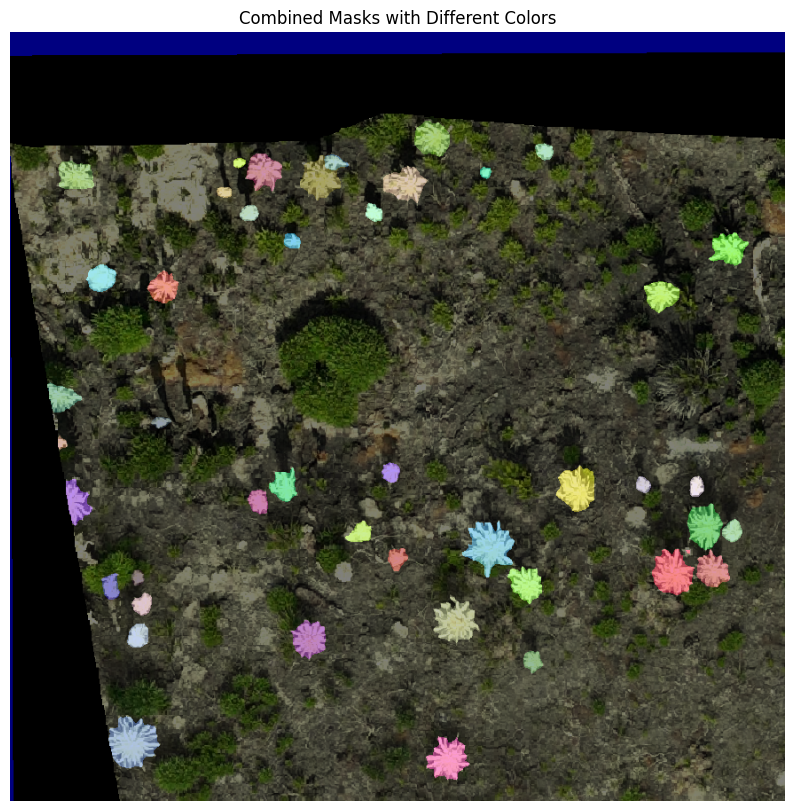

Segmented 44
(867, 874, 4)
(43, 1, 867, 874)


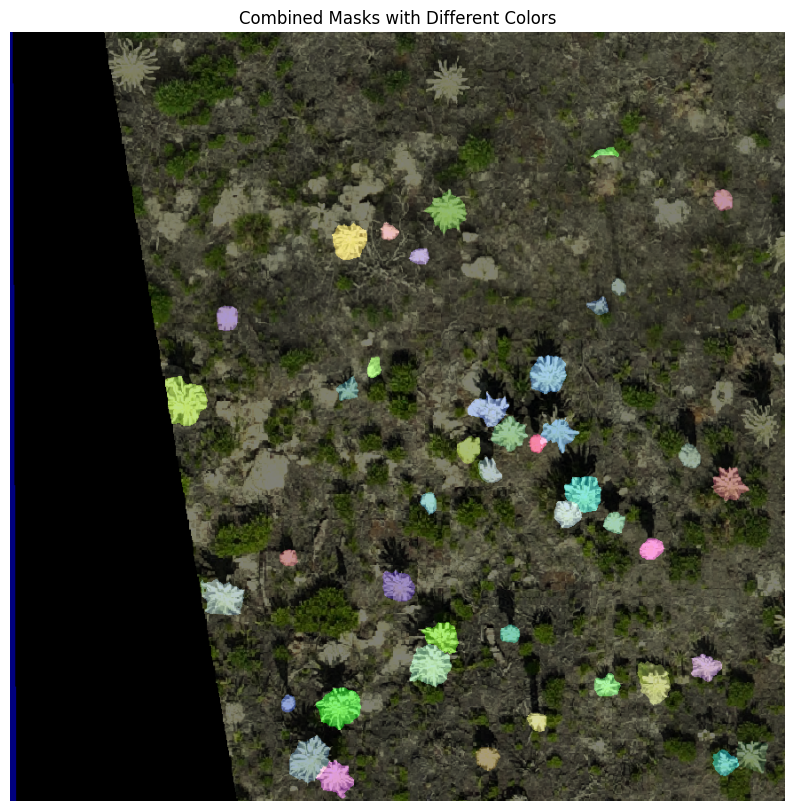

Segmented 87
(867, 874, 4)
(17, 1, 867, 874)


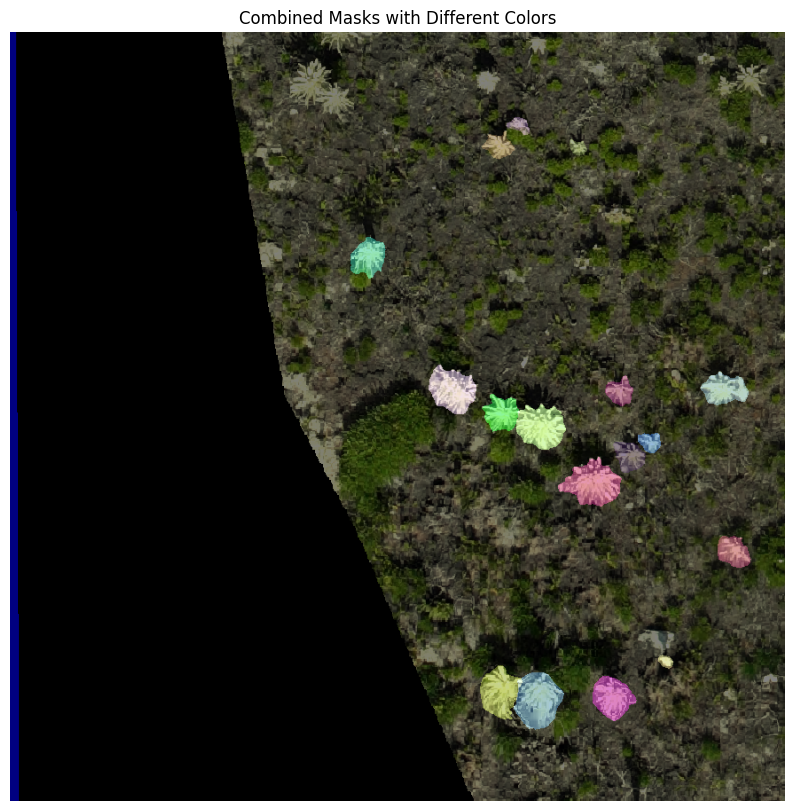

Segmented 104
(608, 874, 4)
(6, 1, 608, 874)


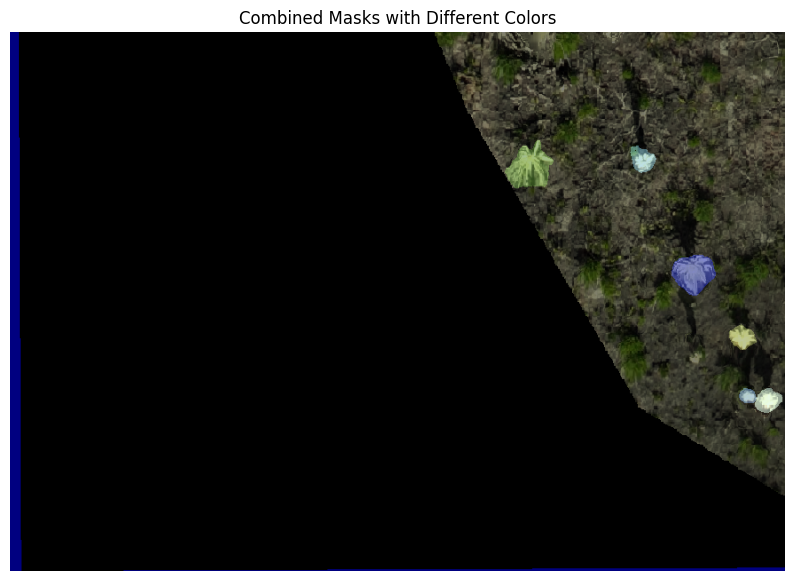

Segmented 110
(867, 874, 4)
(34, 1, 867, 874)


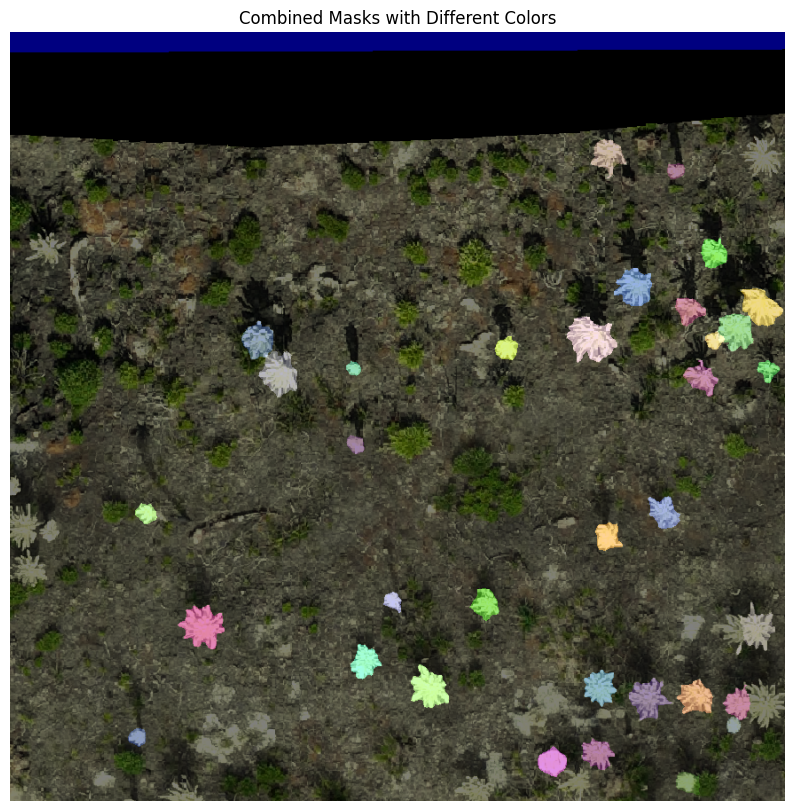

Segmented 144
(867, 874, 4)
(56, 1, 867, 874)


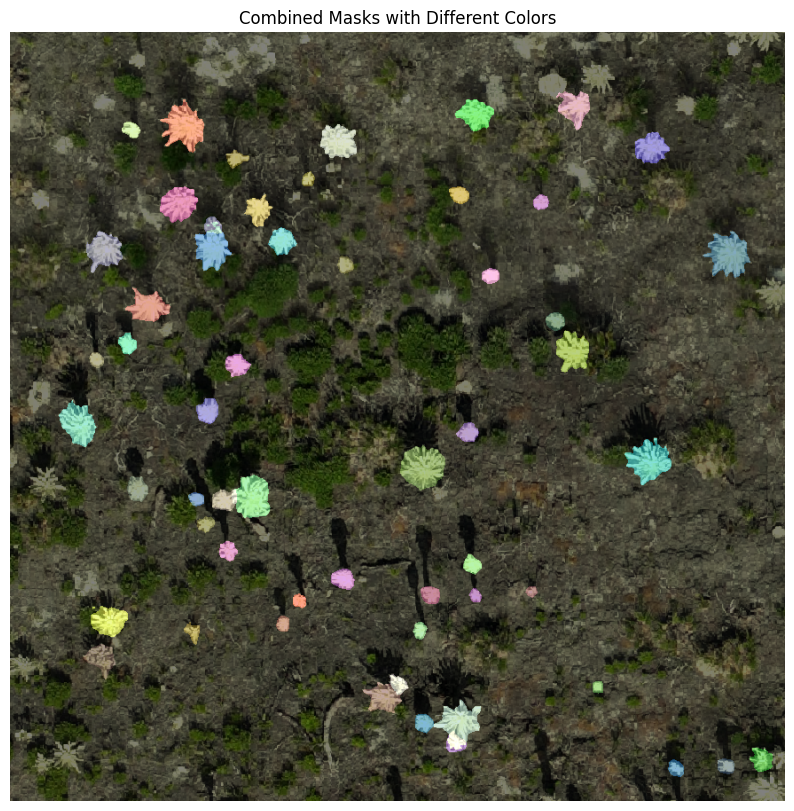

Segmented 200
(867, 874, 4)
(43, 1, 867, 874)


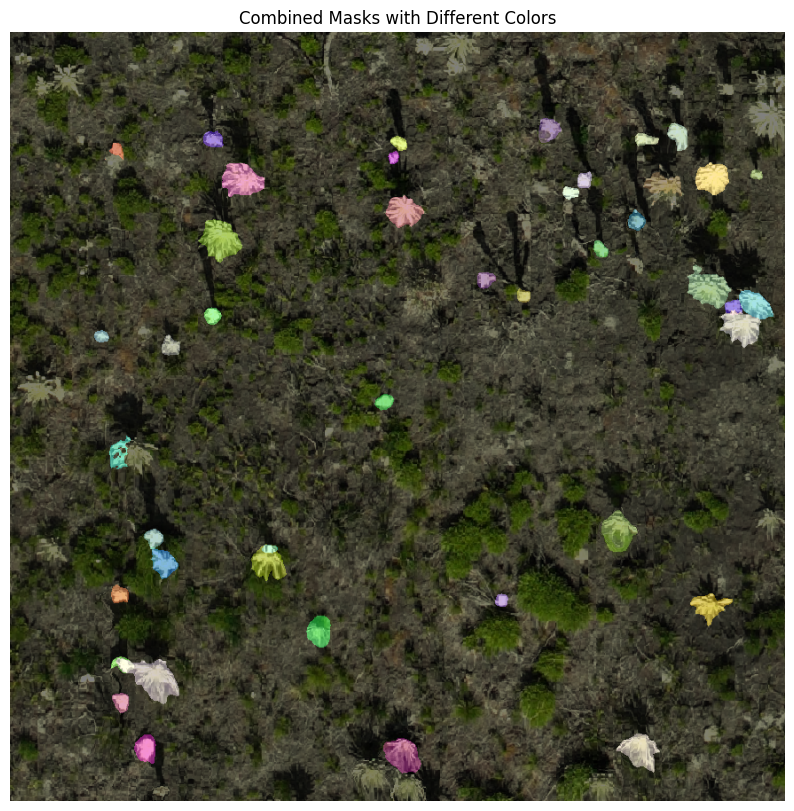

Segmented 243
(608, 874, 4)
(32, 1, 608, 874)


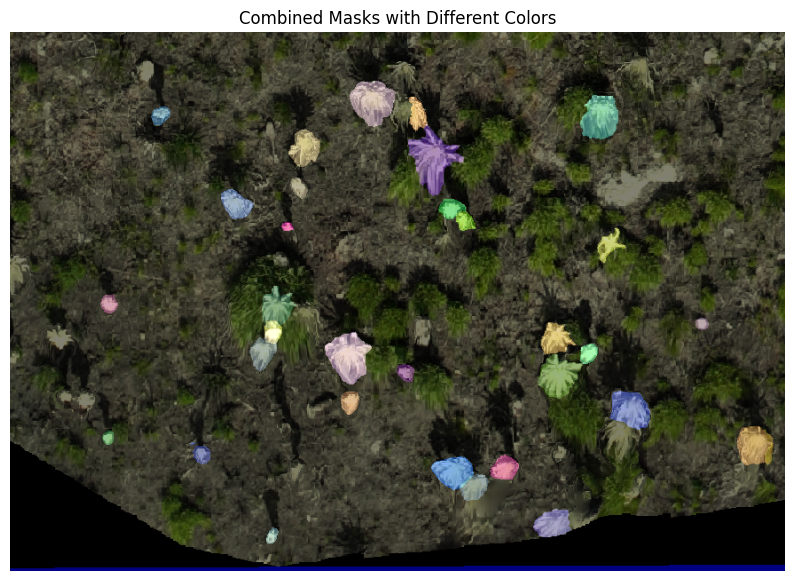

Segmented 275
(867, 874, 4)
(77, 1, 867, 874)


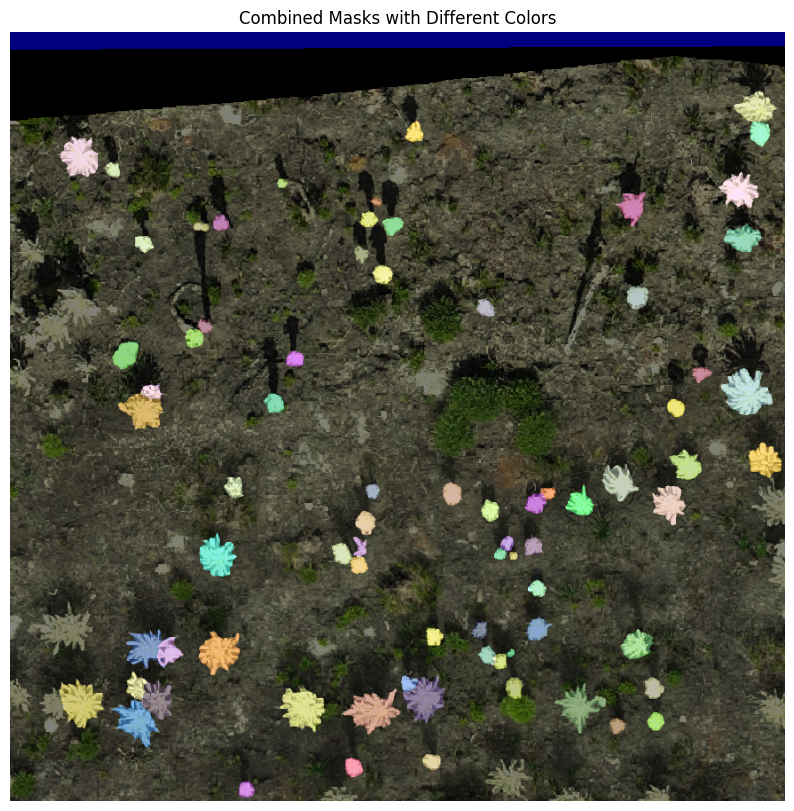

Segmented 352
(867, 874, 4)
(37, 1, 867, 874)


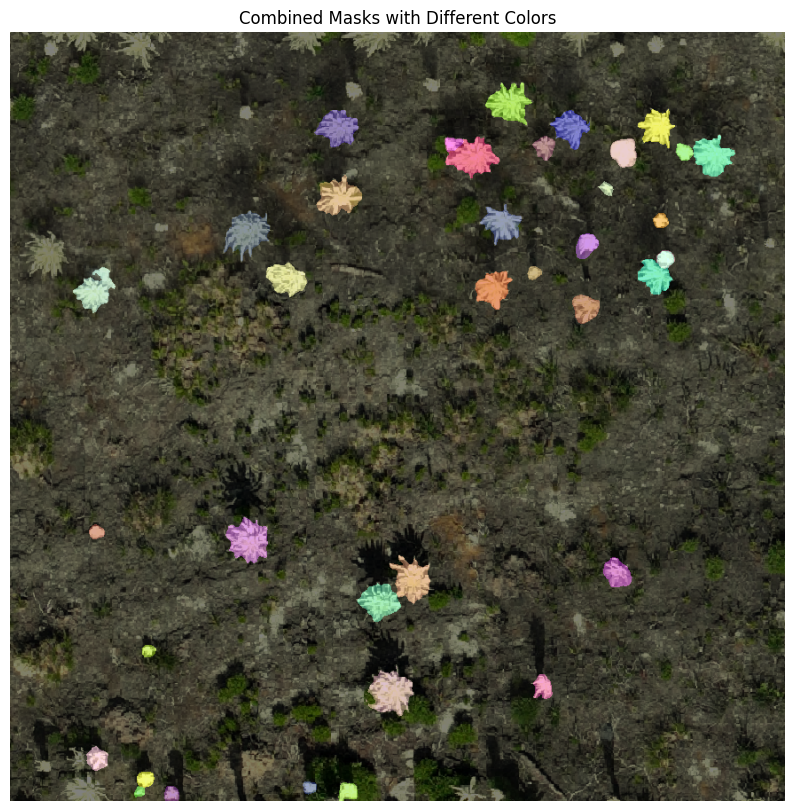

Segmented 389
(867, 874, 4)
(54, 1, 867, 874)


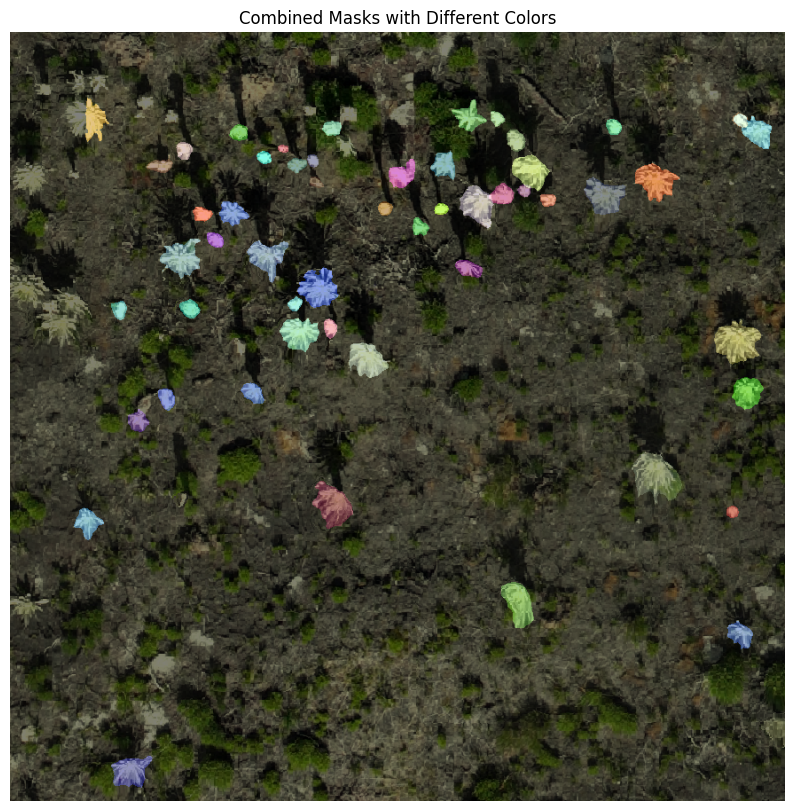

Segmented 443
(608, 874, 4)
(8, 1, 608, 874)


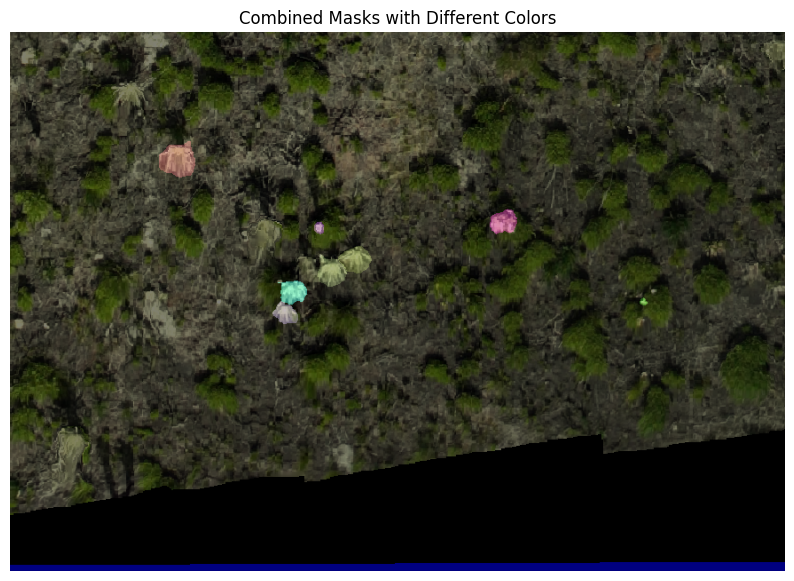

Segmented 451
(867, 874, 4)
(60, 1, 867, 874)


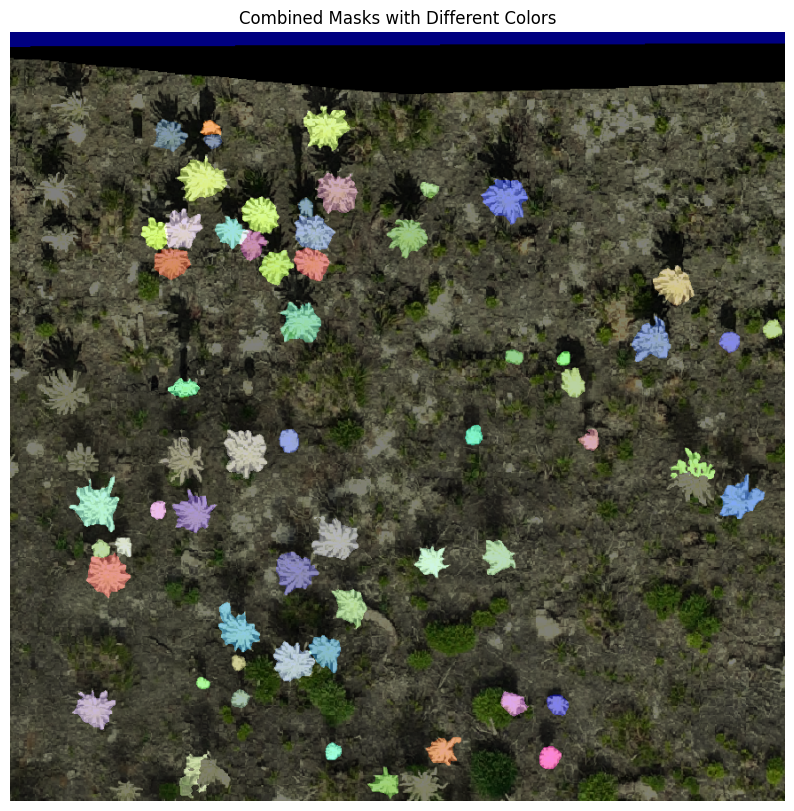

Segmented 511
(867, 874, 4)
(15, 1, 867, 874)


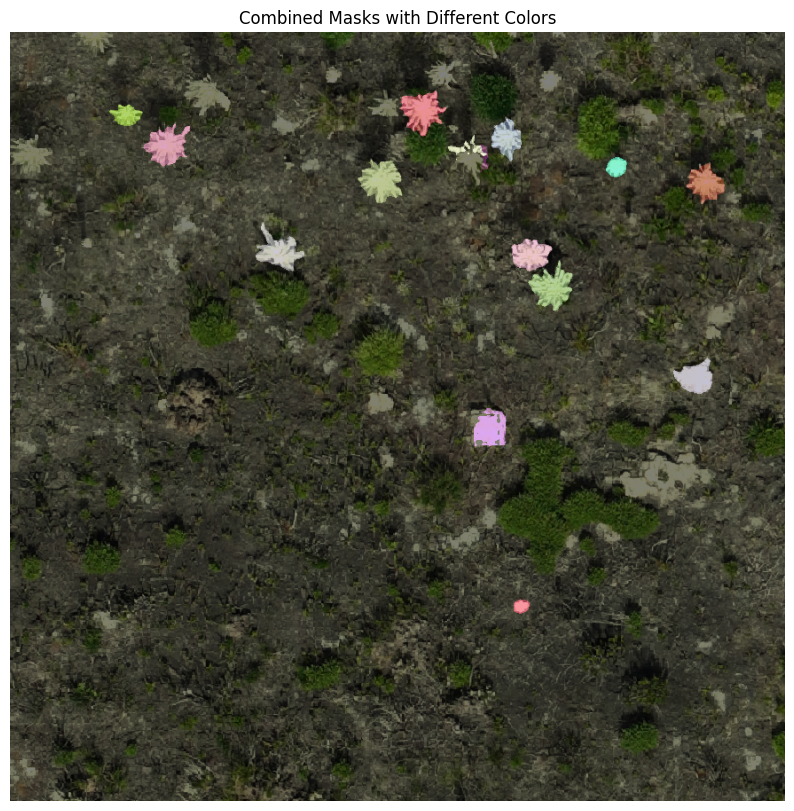

Segmented 526
(867, 874, 4)
(38, 1, 867, 874)


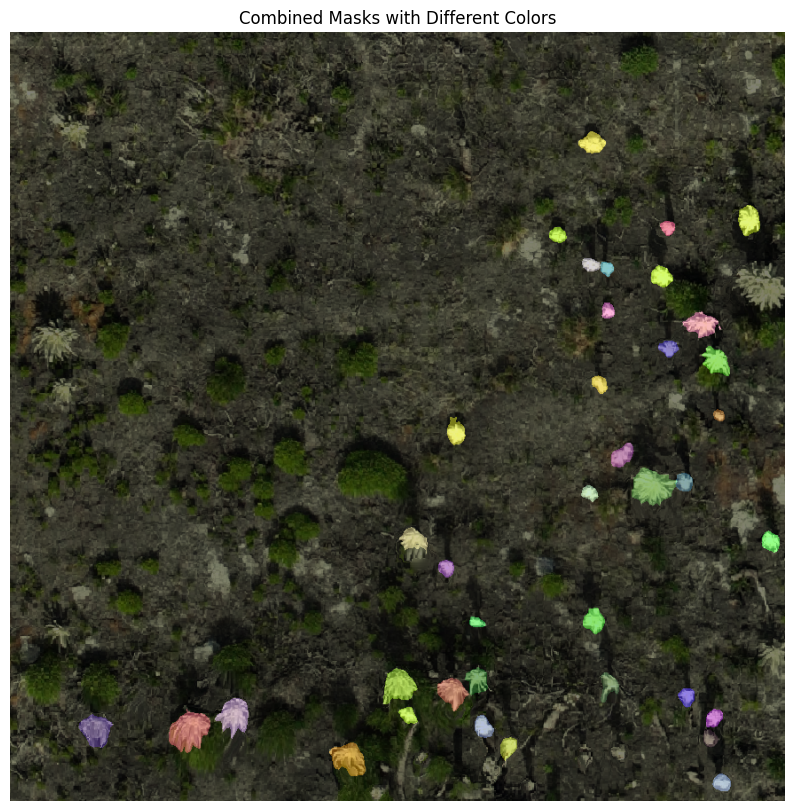

Segmented 564
(608, 874, 4)
(10, 1, 608, 874)


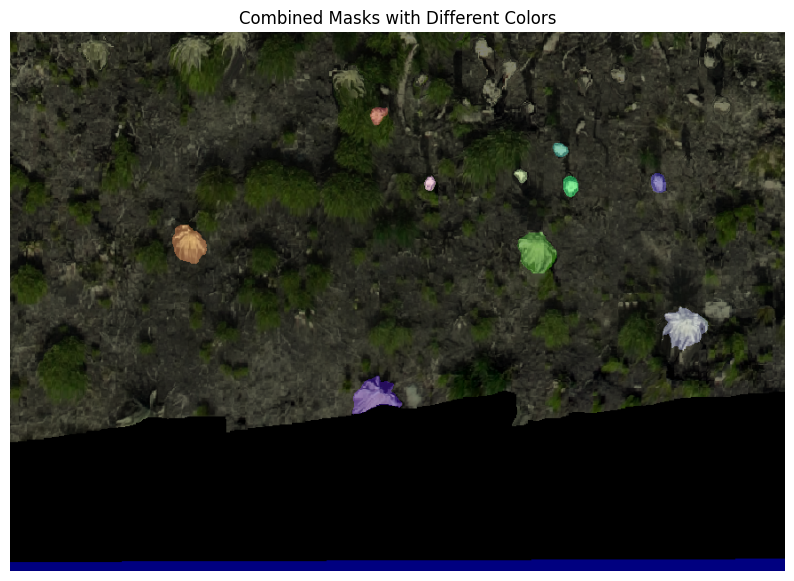

Segmented 574
(867, 874, 4)
(11, 1, 867, 874)


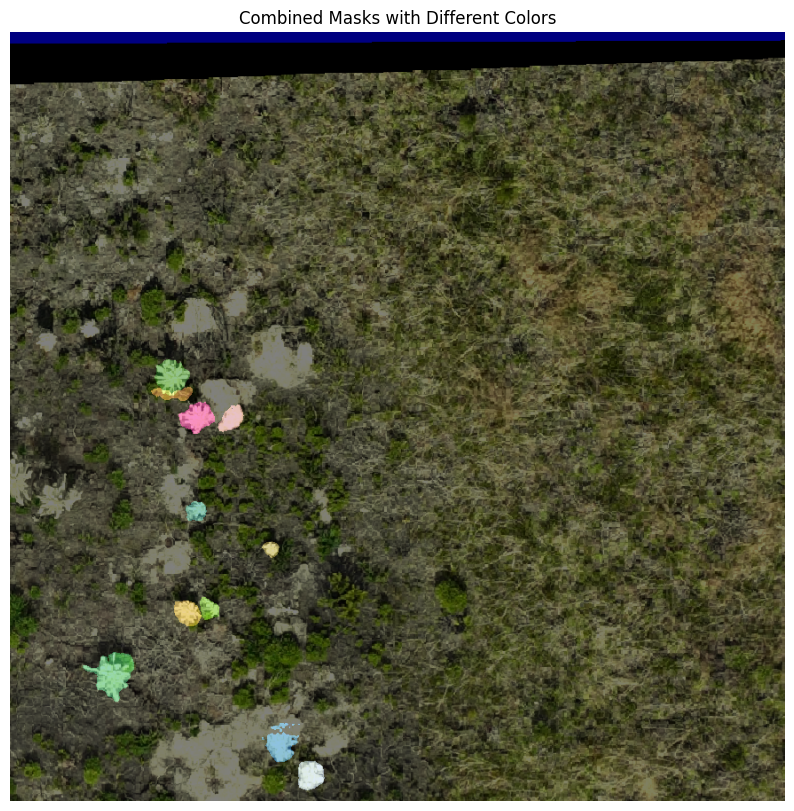

Segmented 585
(867, 874, 4)
(9, 1, 867, 874)


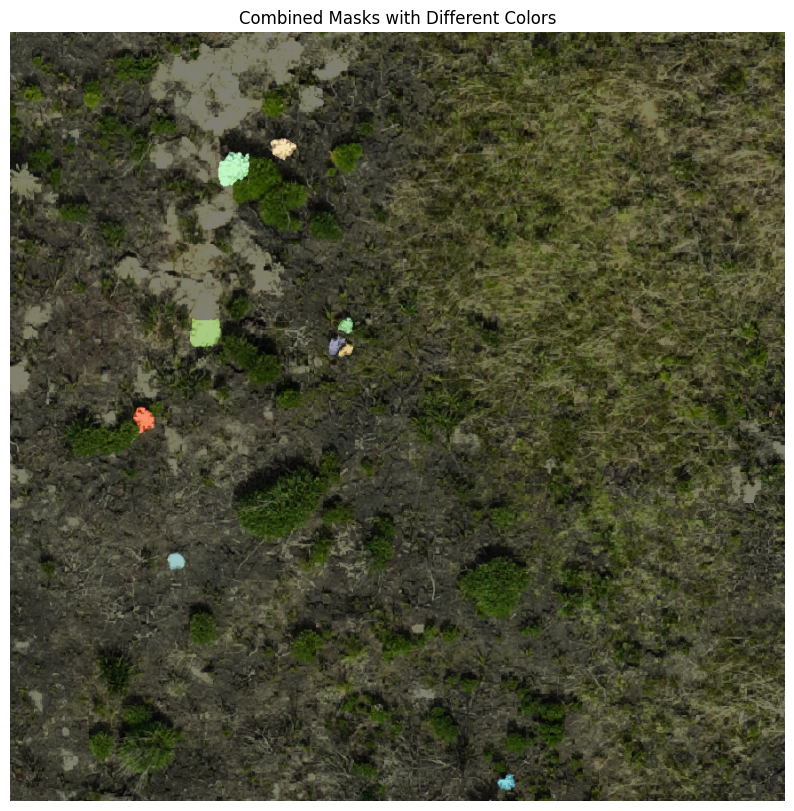

Segmented 594
(867, 874, 4)
(30, 1, 867, 874)


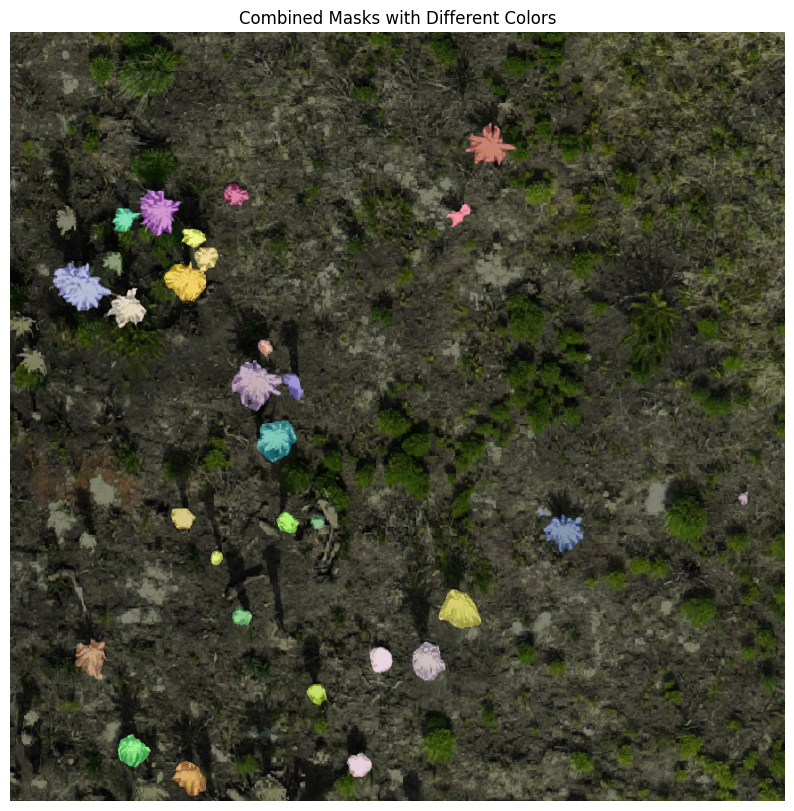

Segmented 624
(608, 874, 4)
(16, 1, 608, 874)


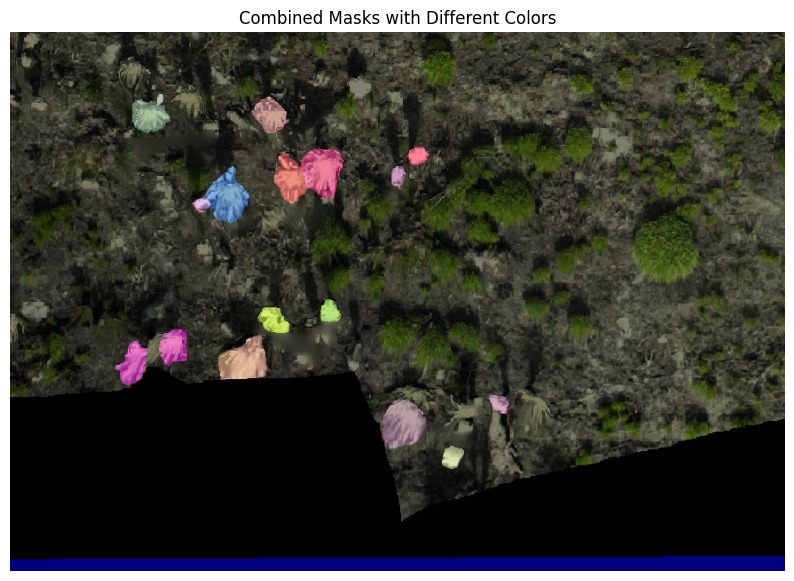

Segmented 640
(867, 874, 4)
(867, 874, 4)
(2, 1, 867, 874)


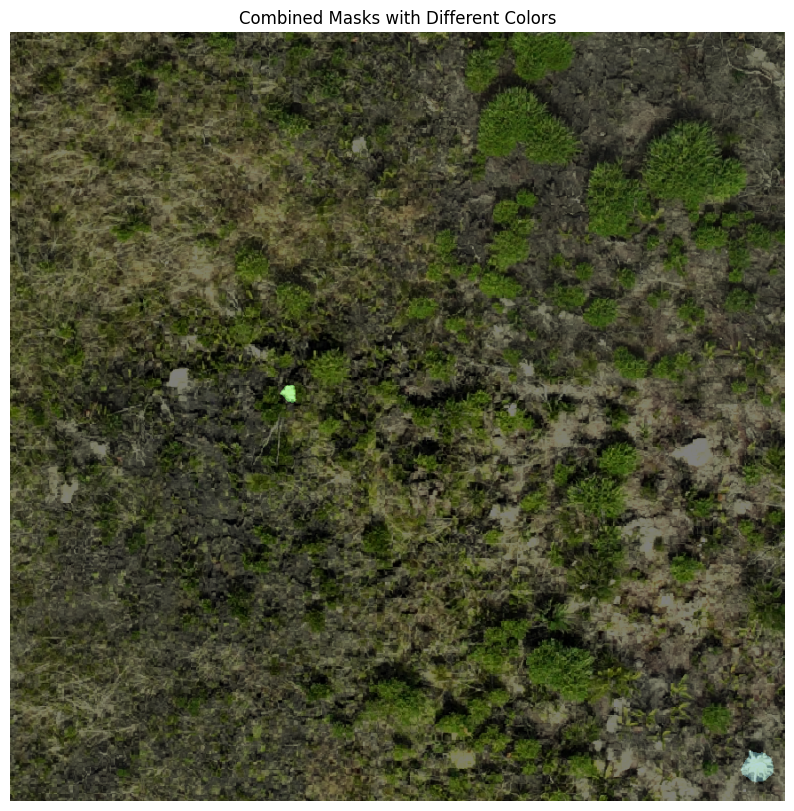

Segmented 642
(867, 874, 4)
(3, 1, 867, 874)


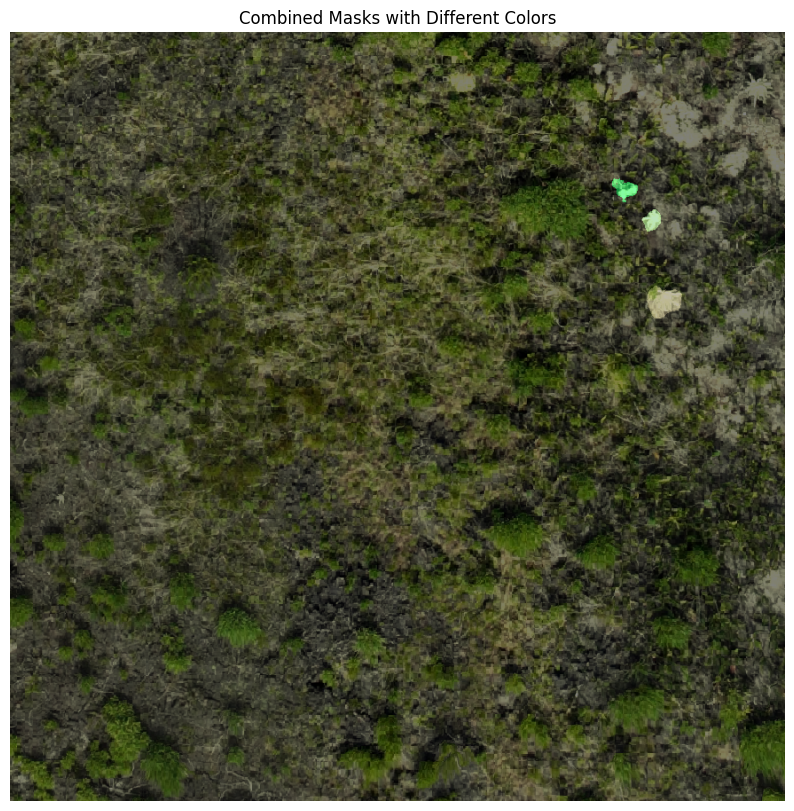

Segmented 645
(608, 874, 4)
(867, 874, 4)
(2, 1, 867, 874)


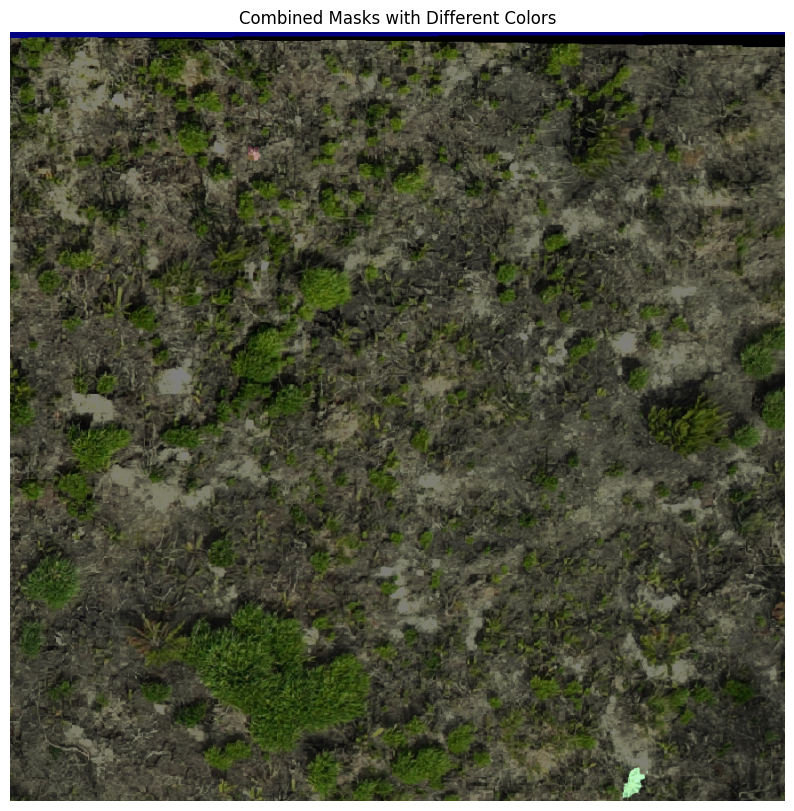

Segmented 647
(867, 874, 4)
(5, 1, 867, 874)


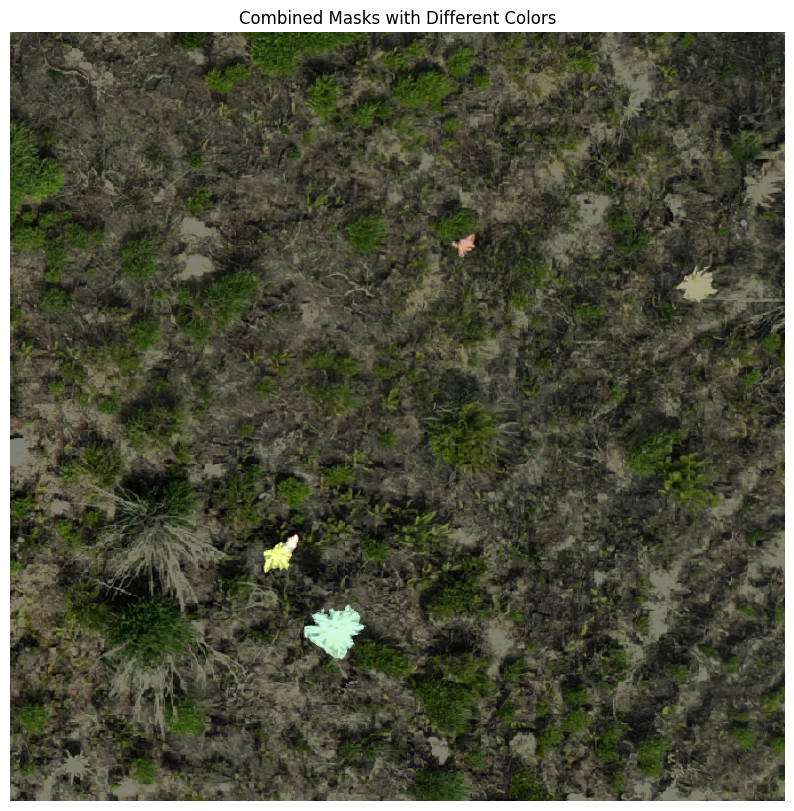

Segmented 652
(867, 874, 4)
(5, 1, 867, 874)


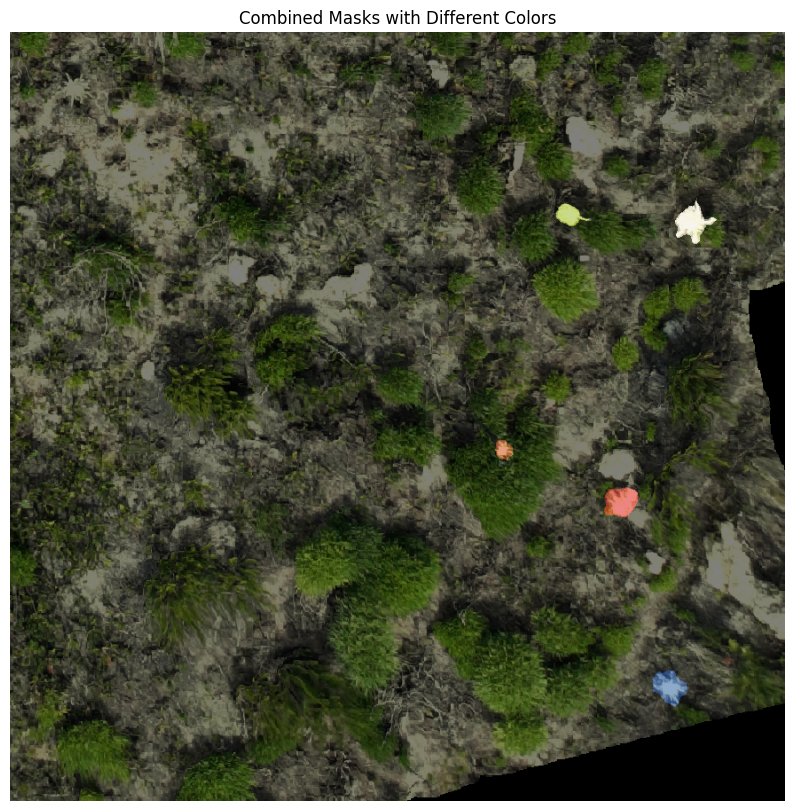

Segmented 657
(608, 874, 4)
(867, 764, 4)
(867, 764, 4)
(6, 1, 867, 764)


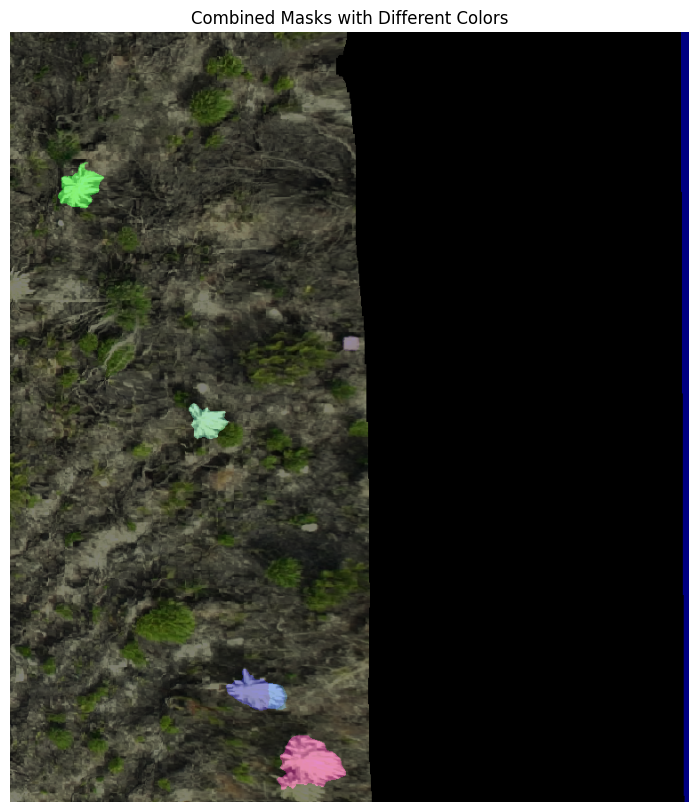

Segmented 663
(867, 764, 4)
(4, 1, 867, 764)


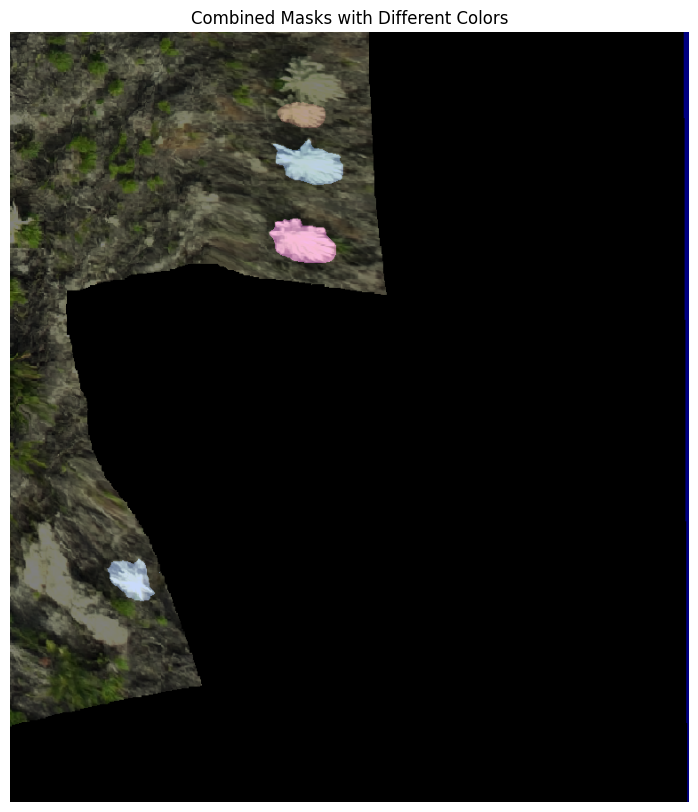

Segmented 667
(608, 764, 4)
PROJCS["WGS 84 / UTM zone 18N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-75],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32618"]]
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
EPSG:32618
Total geometries: 667
Empty geometries: 0
Invalid geometries: 0
NaN geometri

In [ ]:
sam_pipeline(mosaic, mask_predictor, bounding_boxes, output_dir, limit=False)